# Obstacle robustness — figure & table generator

Regenerates the obstacle-robustness charts from `results/obstacle_robustness/<model>/summary.json` (produced by `scripts/evaluation/obstacle_robustness_eval.py`). ADAPTED-rate = obstacle robustness. Saves PDFs to `notebooks/Figures/obstacle_robustness/`.

The last cell renders the goal-head **OV-boost** table (`tab:obstacle-ov-boost`) from `results/notebook_caches/obstacle_ov_boost/<model>/results.json` (produced by `scripts/evaluation/obstacle_ov_boost_eval.py`).

In [1]:
import os, sys
_d=os.getcwd()
while _d!='/' and not os.path.isdir(os.path.join(_d,'src')): _d=os.path.dirname(_d)
sys.path.insert(0,_d); os.chdir(_d)
from src.utils import env_utils
sys.path.insert(0, os.path.join(env_utils.PROJECT_ROOT,'notebooks','fig_n_table_generators'))
import json, glob
import numpy as np, matplotlib.pyplot as plt
import figstyle as F; F.set_style()
from rich import print as rich_print
from rich.table import Table

GROUP='obstacle_robustness'
RES=os.path.join(env_utils.DEFAULT_RESULTS_DIR,'obstacle_robustness')
LEVELS=['aligned','easy','hard']
# load every model summary
S={}
for p in sorted(glob.glob(os.path.join(RES,'*','summary.json'))):
    m=os.path.basename(os.path.dirname(p)); S[m]=json.load(open(p))
# order models by hard-ADAPTED (desc); core model first if present
def hard(m): return S[m]['by_level']['hard']['adapted'] or 0
MODELS=sorted(S, key=hard, reverse=True)
CORE='Qwen2.5-Coder-32B-Instruct'
print(f'{len(S)} models:', MODELS)

7 models: ['Olmo-3.1-32B-Instruct', 'Qwen2.5-Coder-32B-Instruct', 'Qwen2.5-72B-Instruct', 'GLM-4-32B-0414', 'Qwen2.5-32B-Instruct', 'Qwen2.5-Coder-14B-Instruct', 'Olmo-3.1-32B-Instruct-SFT']


saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/obstacle_robustness/obstacle_by_datatype.pdf


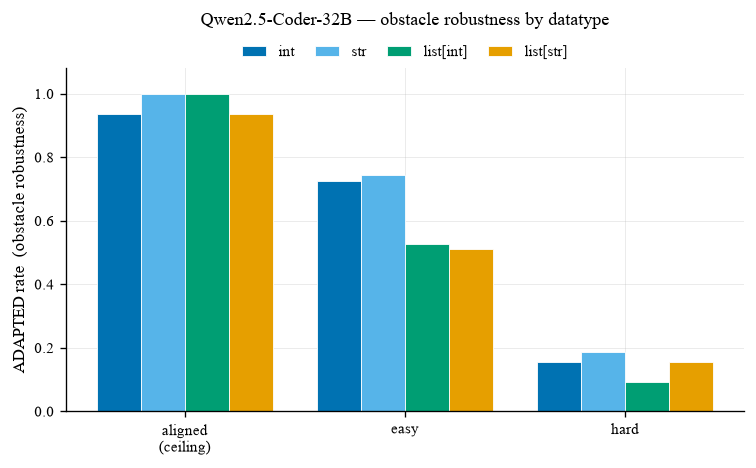

saved /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/obstacle_robustness/obstacle_verdicts.pdf


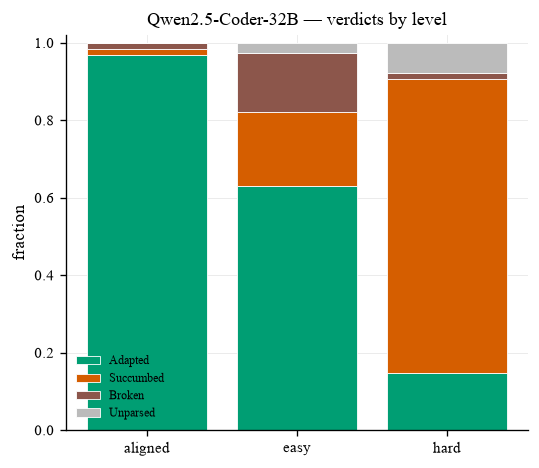

In [2]:
# Coder-32B only: ADAPTED-rate barchart across datatypes.
# All-model comparison lives in the .tex table below.
CORE='Qwen2.5-Coder-32B-Instruct'; d=S[CORE]
DTS=['int','str','list[int]','list[str]']
dcol={'int':'#0072B2','str':'#56B4E9','list[int]':'#009E73','list[str]':'#E69F00'}

# ADAPTED rate by level x datatype — the standalone Coder-32B barchart
fig,ax=plt.subplots(figsize=(6.4,4.0)); x=np.arange(len(LEVELS)); w=0.8/len(DTS)
for i,dt in enumerate(DTS):
    vals=[(d['by_level'][lv]['by_datatype'].get(dt) or 0) for lv in LEVELS]
    ax.bar(x+i*w-0.4+w/2, vals, w, label=dt, color=dcol[dt], edgecolor='white', linewidth=0.5)
ax.set_xticks(x); ax.set_xticklabels([l+('\n(ceiling)' if l=='aligned' else '') for l in LEVELS])
ax.set_ylabel('ADAPTED rate  (obstacle robustness)'); ax.set_ylim(0,1.08)
ax.set_title('Qwen2.5-Coder-32B — obstacle robustness by datatype')
F.legend_top(ax)
fig.tight_layout(); print('saved',F.save_fig(fig,GROUP,'obstacle_by_datatype')); plt.show()


         ADAPTED rate by obstacle level (per model)         
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━┓
┃ model                      ┃ aligned ┃ easy ┃ hard ┃   n ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━┩
│ Olmo-3.1-32B-Instruct      │    0.94 │ 0.57 │ 0.21 │ 409 │
│ Qwen2.5-Coder-32B-Instruct │    0.97 │ 0.63 │ 0.15 │ 409 │
│ Qwen2.5-72B-Instruct       │    0.94 │ 0.57 │ 0.12 │ 409 │
│ GLM-4-32B-0414             │    0.91 │ 0.54 │ 0.12 │ 409 │
│ Qwen2.5-32B-Instruct       │    0.97 │ 0.66 │ 0.12 │ 409 │
│ Qwen2.5-Coder-14B-Instruct │    0.91 │ 0.50 │ 0.09 │ 409 │
│ Olmo-3.1-32B-Instruct-SFT  │    0.89 │ 0.35 │ 0.08 │ 409 │
└────────────────────────────┴─────────┴──────┴──────┴─────┘

wrote /disk/u/arnab/Codes/Projects/goals/notebooks/Figures/obstacle_robustness/obstacle_adapted_by_level.tex


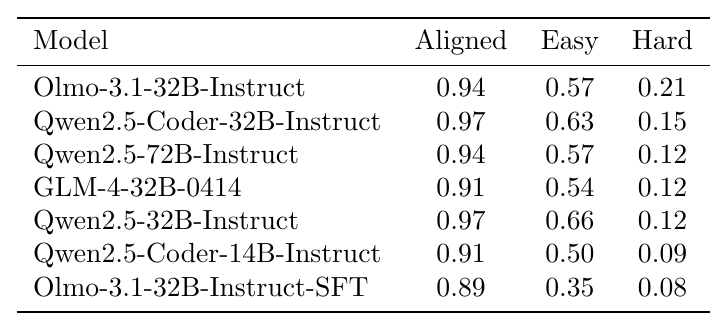

In [3]:
# ── table: ADAPTED rate by level x model (+ emit .tex) ──
t=Table(title='ADAPTED rate by obstacle level (per model)')
t.add_column('model'); [t.add_column(l, justify='right') for l in LEVELS]; t.add_column('n', justify='right')
for m in MODELS:
    t.add_row(m, *[f"{S[m]['by_level'][lv]['adapted'] or 0:.2f}" for lv in LEVELS], str(S[m]['n']))
rich_print(t)

rows=' \\\\\n'.join(m.replace('_','\\_')+' & '+' & '.join(f"{S[m]['by_level'][lv]['adapted'] or 0:.2f}" for lv in LEVELS) for m in MODELS)
tex=('\\begin{tabular}{lccc}\n\\toprule\nModel & Aligned & Easy & Hard \\\\\n\\midrule\n'
     + rows + ' \\\\\n\\bottomrule\n\\end{tabular}')
path=F.save_table(tex, GROUP, 'obstacle_adapted_by_level'); print('wrote', path)
img=F.render_latex_table(tex)
img if img is not None else rich_print('[dim](latex preview unavailable; see rich table above)[/dim]')

In [ ]:
# ── table: goal-head OV boost under the numeric "0 +" obstacle (tab:obstacle-ov-boost) ──
# one block per derailed case: baseline continuation · GoalScope read-out @ '+' · OV-boost x2 continuation
OVB=os.path.join(env_utils.DEFAULT_RESULTS_DIR,'notebook_caches','obstacle_ov_boost',CORE,'results.json')
RESULTS=json.load(open(OVB))

def _tex(s):
    s = s or ""
    for a, b in [("\\", "\\textbackslash{}"), ("&", "\\&"), ("%", "\\%"), ("$", "\\$"),
                 ("#", "\\#"), ("_", "\\_"), ("{", "\\{"), ("}", "\\}"),
                 ("~", "\\textasciitilde{}"), ("^", "\\textasciicircum{}")]:
        s = s.replace(a, b)
    return s

def _verd(v):
    col = "ForestGreen" if v in ("ADAPTED", "ESCAPED") else "BrickRed"
    return f"\\textcolor{{{col}}}{{\\textsc{{{v.lower()}}}}}"

def _rhs(gen):
    return f"\\texttt{{\\textcolor{{gray}}{{0 +}} {_tex(gen)}}}"

t=Table(title=f'OV boost x2 under the "0 +" obstacle — {CORE} ({len(RESULTS)} derailed cases)')
for c in ['dt','frontier','baseline','read-out @ +','OV-boost x2']: t.add_column(c)
blocks=[]
for r in RESULTS:
    t.add_row(r['dt'], r['pid'], f"0 + {r['base_gen']}  ({r['base_verdict']})", r['readout'],
              f"0 + {r['boost_gen']}  ({r['boost_verdict']})")
    fr = f"\\multirow{{3}}{{*}}{{\\texttt{{{_tex(r['pid'])}}}}}"
    blocks.append("\n".join([
        f"{fr} & baseline & {_rhs(r['base_gen'])}~{_verd(r['base_verdict'])} \\\\",
        f" & readout @ \\texttt{{+}} & {_tex(r['readout'])} \\\\",
        f" & OV-boost $\\times2$ & {_rhs(r['boost_gen'])}~{_verd(r['boost_verdict'])} \\\\"]))
rich_print(t)
tex=("\\begin{tabular}{@{}l l p{7.6cm}@{}}\n\\toprule\n"
     "frontier & run & continuation / readout \\\\\n\\midrule\n" + "\n\\midrule\n".join(blocks)
     + "\n\\bottomrule\n\\end{tabular}")
path=F.save_table(tex, GROUP, 'obstacle_ov_boost'); print('wrote', path)
img=F.render_latex_table(tex, preamble=r"\usepackage{booktabs,array,multirow}\usepackage[dvipsnames]{xcolor}")
img if img is not None else rich_print('[dim](latex preview unavailable; see rich table above)[/dim]')